# What does more premium buy?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/marc272/crc-docs/blob/parametric/notebooks/what_does_more_premium_buy.ipynb)

A parametric cover pays an agreed amount when a measured number, here the rain on
the wettest day of the year, passes an agreed level. The
[parametric insurance primer](parametric_insurance_primer.ipynb) drew one by hand
for an imaginary Toronto brewery. Here the parametric module of
[crc-sdk](https://github.com/RiskThinking/crc-sdk) chooses the terms itself, once
for each premium budget, and we ask one question: **what does more premium buy?**

Each budget gets its own design, for one stated goal, and each design is tested
on simulated years it never saw.

**The one thing to take away: a budget frontier shows what each budget buys, and
in which years. Choosing the budget stays with the brewery.**

On Colab choose **Runtime → Run all**; no account needed. The first run installs
crc-sdk and downloads one small CRC Open file, in a minute or two.

## Setup

In [1]:
#@title Install packages (Colab)
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None

# crc_sdk.parametric is not in a crc-sdk release yet: install it from its development branch.
CRC_SDK = "crc-sdk[geometry,parametric] @ git+https://github.com/marc272/crc-sdk@parametric"


def has_parametric():
    spec = importlib.util.find_spec("crc_sdk")
    return spec is not None and spec.origin is not None and (Path(spec.origin).parent / "parametric").is_dir()


def pip_install(*arguments):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--disable-pip-version-check", *arguments])


if IN_COLAB or not has_parametric():
    if importlib.util.find_spec("pip") is None:  # a bare virtual environment
        subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"], stdout=subprocess.DEVNULL)
    pip_install(CRC_SDK, "plotly>=6,<7", "pandas>=2.2")
    if not has_parametric():  # a crc-sdk release of the same version number was already installed
        pip_install("--force-reinstall", "--no-deps", CRC_SDK)
    importlib.invalidate_caches()

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"

In [2]:
import warnings

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
from IPython.display import display
from plotly.colors import sample_colorscale
from plotly.subplots import make_subplots

from crc_sdk.impacts import ImpactCalibration, ImpactExpression
from crc_sdk.parametric import (
    Budget, Cover, EvaluationMetadata, Free, HazardNoise, IndexDefinition, Limit, LossModel, MetricOptions,
    PiecewiseLinearPayout, PurePremium, WeightedCVaR, design_frontier, sample_curve, setup_text,
)
from crc_sdk.workflows import HazardDataset
from crc_sdk.workflows.distributions import ReturnPeriodExtrapolationWarning

# About 1 simulated year in 1,000 falls outside the return periods the curve was fitted on
# (1.001 to 1,000 years), where it is extrapolated. We accept that, and setup_text counts those years.
warnings.simplefilter("ignore", ReturnPeriodExtrapolationWarning)

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"
pio.defaults.default_width = 1000

# The primer's folder: the same CRC Open file, downloaded once for both notebooks.
DATA = Path("data") / "parametric_primer"
DATA.mkdir(parents=True, exist_ok=True)

# As in the primer, orange is always the loss and blue the payout.
INK, BLUE, ORANGE, MUTED = "#52514e", "#2a78d6", "#eb6834", "#8a8880"
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def layout(fig, title, setup, height=520, bottom=70, top=140, **kwargs):
    """Style a chart and state its setup under the title, so the numbers never lose it."""
    fig.update_layout(title=dict(text=title, x=0.01, y=0.97, yanchor="top",
                                 subtitle=dict(text=setup, font=dict(size=11, color=MUTED))),
                      font=FONT, height=height, margin=dict(l=75, r=30, t=top, b=bottom), hoverlabel=dict(font_size=13), **kwargs)
    return fig


def cad(value):
    return f"CAD {value:,.0f}"

## The brewery, again

The setting is the primer's: **Wet Basement Brewing** is made up, and its CAD 5
million value and damage curve are illustrations. The cover pays on CRC Open's
`rx1day` for the hexagon around the site, under SSP5-8.5 in 2030. CRC Open has no
historical baseline, so everything below describes that future.
`HazardNoise(0.25)` models the gap between the rain on the hexagon and the rain at
the brewery; its σ is an assumption of this illustration.

We draw two separate sets of years: **design years**, on which the module chooses
the terms, and **fresh years**, on which every number below is measured.

In [3]:
RELEASE, PATHWAY, HORIZON = "ssp585-global-2026-10-20-v1", "ssp585", 2030
ASSET = {"asset_id": "Wet Basement Brewing", "longitude": -79.38, "latitude": 43.65, "value_cad": 5_000_000.0}

# Downloads and checks the CRC Open file once, then reads the cached copy.
dataset = (
    HazardDataset.crc_open(release=RELEASE)
    .hazards(["rx1day"])
    .horizons([HORIZON])
    .for_area((-79.40, 43.63, -79.36, 43.67))  # (west, south, east, north), enough to find the site's hexagon
    .cache(DATA / "crc-open", mode="reuse")
    .ensure_materialized()
)
metadata = dataset.metadata()
curve_row = (
    dataset.for_assets(pa.Table.from_pylist([ASSET]))
    .select(hazard_names=["rx1day"], horizons=[HORIZON], pathways=[PATHWAY])
    .asset_curves()
    .to_pylist()[0]
)
DAMAGE = ImpactExpression.tabulated(
    [(40.0, 0.0), (50.0, 0.02), (60.0, 0.06), (75.0, 0.15), (100.0, 0.30)],
    calibration=ImpactCalibration(exposure_variable="rx1day", exposure_unit="mm/day",
                                  impact_metric="damage_ratio", impact_unit="1"),
    clamp={"minimum": 0.0, "maximum": 1.0},
)

SIGMA = 0.25
N_YEARS = 2_000 if CI else 20_000
loss_model = LossModel(DAMAGE, value=ASSET["value_cad"], value_unit="CAD")


def simulate(seed):
    return sample_curve(curve_row, metadata=metadata, n_draws=N_YEARS, rng=np.random.default_rng(seed),
                        loss_model=loss_model, basis_risk=HazardNoise(SIGMA), asset_id=ASSET["asset_id"])


design_years, fresh_years = simulate(seed=42), simulate(seed=7)  # the primer's seeds, so the primer's years
print(f"{N_YEARS:,} design years and {N_YEARS:,} fresh years from CRC Open rx1day ({metadata.value_unit}), release {RELEASE}, "
      f"pathway {PATHWAY}, horizon {HORIZON}, hexagon {curve_row['cell_index']:x}.")
print(f"Licence: {metadata.source.licence}. Attribution: {metadata.source.attribution}.")

SETUP = (f"Setup: one imaginary asset · annual basis, one draw = one year · basis risk: HazardNoise, σ = {SIGMA} · "
         f"CRC Open rx1day, SSP5-8.5, {HORIZON} (no historical baseline) · hypothetical damage and value ·<br>"
         f"goal: weighted CVaR, α = 0.9, β = 0.9 · pure premium · one design per budget, chosen on {N_YEARS:,} design years")

20,000 design years and 20,000 fresh years from CRC Open rx1day (mm/day), release ssp585-global-2026-10-20-v1, pathway ssp585, horizon 2030, hexagon 852b9bc7fffffff.
Licence: CC-BY-NC-4.0. Attribution: Riskthinking.AI bias-corrected climate distributions.


## One goal, many budgets

**The shape.** The cover pays nothing up to 45 mm. From there its payout may rise
at 50, 55, 60, 70 and 85 mm, never above CAD 1 million in a year. The module
chooses those five amounts.

**The goal.** `WeightedCVaR(alpha=0.9, beta=0.9)` keeps small what the payout
leaves uncovered in the worst years. With U the uncovered part of a year's loss, it
minimises 0.9 · CVaR₀.₉(U) + 0.1 · E[U], where CVaR₀.₉(U) is the average of U over
its worst tenth of the years.

**The price.** The pure premium, what the cover pays out on average: the
break-even price (a real premium is higher, as the primer's section 4 shows). A
budget is the most the brewery will pay a year, priced on the design years.

`design_frontier` solves one design per budget, each on its own, reads each on the
fresh years, and returns one row per budget:

In [4]:
index = IndexDefinition("rx1day", "mm/day", aggregation="annual_maximum")
KNOTS, LIMIT = [45.0, 50.0, 55.0, 60.0, 70.0, 85.0], 1_000_000.0
# Nothing at or below 45 mm; the five amounts after it are free.
template = Cover(index, PiecewiseLinearPayout(KNOTS, [0.0, Free(), Free(), Free(), Free(), Free()]),
                 payout_unit="CAD", label="Protect the worst years")
BUDGETS = (5_000.0, 10_000.0, 20_000.0, 30_000.0, 45_000.0, 60_000.0, 90_000.0, 120_000.0, 150_000.0)  # CAD a year

frontier = design_frontier(
    template, design_years, WeightedCVaR(alpha=0.9, beta=0.9),
    budgets=[Budget(amount=budget) for budget in BUDGETS], pricing=PurePremium(), limit=Limit(LIMIT),
    evaluate_on=fresh_years, split="out_of_sample",
    metric_options=MetricOptions(betas=(0.9,), return_periods=(10.0, 100.0)),
)
rows = frontier.to_pandas().set_index("budget_amount")

# Each row's designed terms, from the cover documents the table's metadata holds.
documents = {entry.hash: entry.document for entry in EvaluationMetadata.from_table(frontier).covers}
covers = [Cover.from_document(documents[cover_hash]) for cover_hash in rows["cover_hash"]]
# The rain above which each cover pays (the knot before its first amount above zero), and whether every amount is at the cap.
rows["pays_above"] = [KNOTS[next(knot for knot, level in enumerate(cover.payout.levels) if level > 0) - 1] for cover in covers]
rows["at_cap"] = [min(cover.payout.levels[1:]) >= LIMIT * (1 - 1e-9) for cover in covers]
print(f"{len(rows)} designs, one per budget, each read on the {N_YEARS:,} fresh years.")

Running HiGHS 1.16.0 (git hash: f3f113d): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details


9 designs, one per budget, each read on the 20,000 fresh years.


## Where the money goes

Each line is one budget's designed payout.

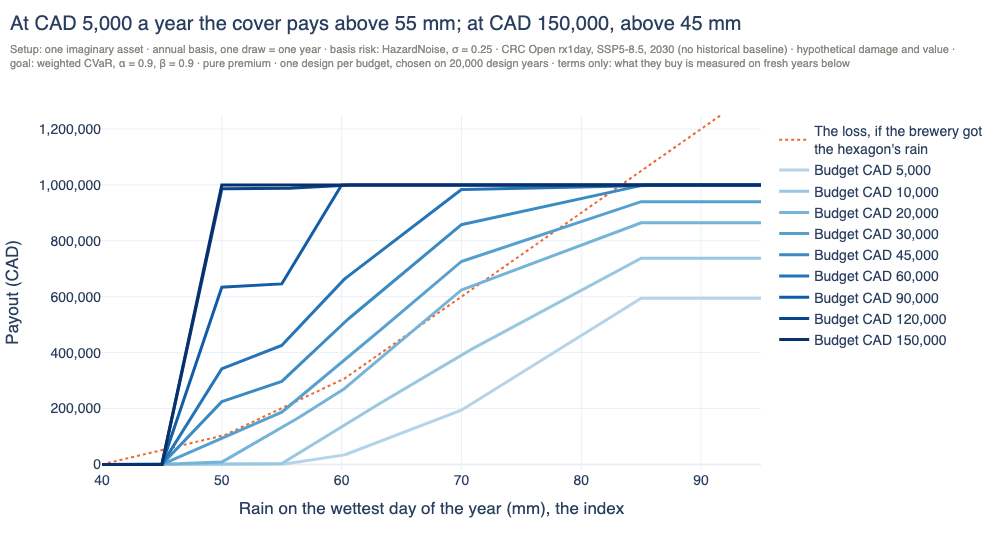

In [5]:
plot_rain = np.linspace(40.0, 95.0, 221)
fig = go.Figure()
fig.add_trace(go.Scatter(x=plot_rain, y=ASSET["value_cad"] * np.asarray(DAMAGE.evaluate(plot_rain), dtype=float),
                         mode="lines", name="The loss, if the brewery got<br>the hexagon's rain", line=dict(color=ORANGE, width=2, dash="dot"),
                         hovertemplate="%{x:.0f} mm: loss CAD %{y:,.0f}<extra></extra>"))
for budget, cover, shade in zip(rows.index, covers, sample_colorscale("Blues", np.linspace(0.3, 1.0, len(rows)))):
    fig.add_trace(go.Scatter(x=plot_rain, y=cover.payout_values(plot_rain), mode="lines", name=f"Budget {cad(budget)}",
                             line=dict(color=shade, width=3),
                             hovertemplate=f"Budget {cad(budget)}<br>" + "%{x:.0f} mm: pays CAD %{y:,.0f}<extra></extra>"))
low, high = rows.iloc[0], rows.iloc[-1]
layout(fig, f"At {cad(low.name)} a year the cover pays above {low.pays_above:.0f} mm; at {cad(high.name)}, above {high.pays_above:.0f} mm",
       SETUP + " · terms only: what they buy is measured on fresh years below",
       xaxis_title="Rain on the wettest day of the year (mm), the index",
       yaxis=dict(title="Payout (CAD)", tickformat=",.0f", range=[-20_000, 1_250_000]), height=540, top=115)
fig.show()

Read the lines from light to dark. On this brewery, under the pure premium, the
goal puts the first dollars on the wettest days, where the worst years are most
likely: the smallest budgets pay only on rare, very wet days. Larger budgets raise
the payout and reach down towards 45 mm, so the cover pays in more years, until
the amounts meet the CAD 1 million cap.

## What it buys

Now the same designs on the fresh years: on the left, the loss they reach; on the
right, a bad year's cost with each cover, premium included, against no cover.

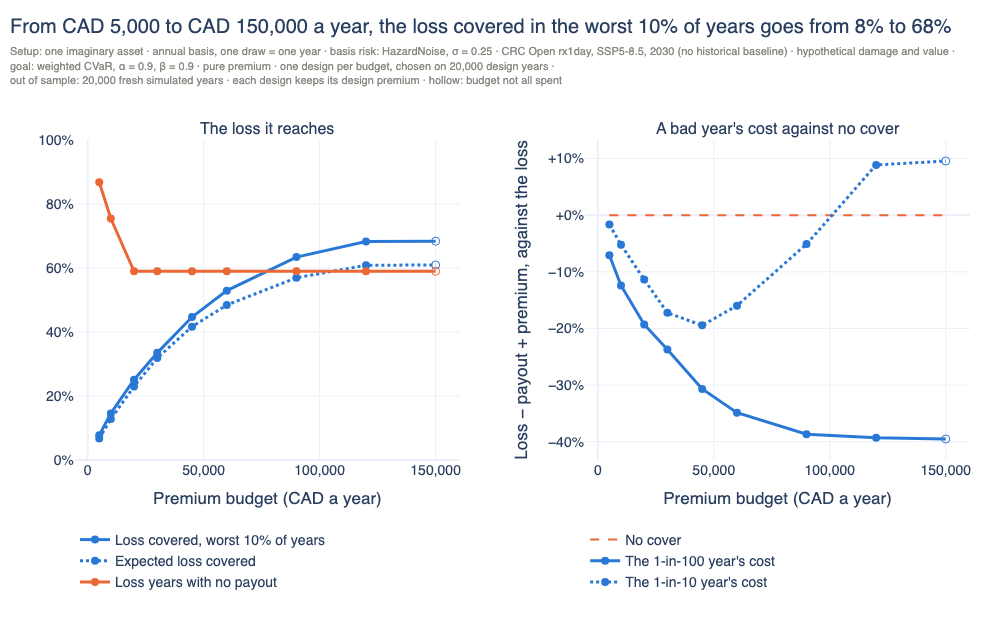

From a budget of CAD 150,000, the design spends CAD 121,224 a year (81% of the budget): every amount it chooses is at the CAD 1,000,000 cap, so a larger budget buys nothing more.


In [6]:
budgets = rows.index.to_numpy()
# A hollow marker: a design that leaves part of its budget unspent.
symbols = ["circle" if use > 0.999 else "circle-open" for use in rows["budget_use"]]
fig = make_subplots(rows=1, cols=2, horizontal_spacing=0.14,
                    subplot_titles=("The loss it reaches", "A bad year's cost against no cover"))
for column, name, color, dash in [("tail_coverage_b0_9", "Loss covered, worst 10% of years", BLUE, "solid"),
                                  ("coverage_ratio", "Expected loss covered", BLUE, "dot"),
                                  ("false_negative_rate_l0", "Loss years with no payout", ORANGE, "solid")]:
    fig.add_trace(go.Scatter(x=budgets, y=rows[column], mode="lines+markers", name=name, legend="legend",
                             line=dict(color=color, width=3, dash=dash), marker=dict(size=8, symbol=symbols),
                             hovertemplate="Budget CAD %{x:,.0f}: %{y:.1%}<extra></extra>"), row=1, col=1)
fig.add_trace(go.Scatter(x=[budgets[0], budgets[-1]], y=[0, 0], mode="lines", name="No cover", legend="legend2",
                         line=dict(color=ORANGE, width=2, dash="dash"), hoverinfo="skip"), row=1, col=2)
for period, dash in [(100, "solid"), (10, "dot")]:
    net, alone = rows[f"net_loss_rp{period}"], rows[f"loss_rp{period}"]  # loss − payout + premium; the loss alone
    fig.add_trace(go.Scatter(x=budgets, y=net / alone - 1, customdata=np.column_stack([net, alone]), mode="lines+markers",
                             name=f"The 1-in-{period} year's cost", legend="legend2", line=dict(color=BLUE, width=3, dash=dash),
                             marker=dict(size=8, symbol=symbols),
                             hovertemplate=(f"Budget CAD %{{x:,.0f}}: a 1-in-{period} year costs CAD %{{customdata[0]:,.0f}} "
                                            "with the cover, CAD %{customdata[1]:,.0f} without<extra></extra>")), row=1, col=2)
fig.update_xaxes(title_text="Premium budget (CAD a year)", tickformat=",.0f")
fig.update_yaxes(tickformat=".0%", range=[0, 1], row=1, col=1)
fig.update_yaxes(title_text="Loss − payout + premium, against the loss", tickformat="+.0%", row=1, col=2)
tail = rows["tail_coverage_b0_9"]
layout(fig, f"From {cad(budgets[0])} to {cad(budgets[-1])} a year, the loss covered in the worst 10% of years goes from {tail.iloc[0]:.0%} to {tail.iloc[-1]:.0%}",
       SETUP + f" ·<br>out of sample: {N_YEARS:,} fresh simulated years · each design keeps its design premium · hollow: budget not all spent",
       height=620, top=140, bottom=160,
       legend=dict(orientation="v", yanchor="top", y=-0.2, x=0), legend2=dict(orientation="v", yanchor="top", y=-0.2, x=0.57))
fig.show()

unspent = rows[rows["budget_use"] < 0.999]
if len(unspent):
    first = unspent.iloc[0]
    print(f"From a budget of {cad(first.name)}, the design spends {cad(first.premium)} a year ({first.budget_use:.0%} of the budget)"
          + (f": every amount it chooses is at the {cad(LIMIT)} cap, so a larger budget buys nothing more." if first.at_cap else
             ": more payout would not lower its goal on the design years."))

On this brewery, under the pure premium and at these budgets:

- **The worst years.** The share of the loss covered in the worst 10% of years
  rises with the budget until the cap, and stays above the share of the expected
  loss covered. That is where this goal puts its weight.
- **The years the index misses.** Loss years with no payout fall until the cover
  pays from just above 45 mm. The rest had a loss while the hexagon's rain stayed
  at or below 45 mm, where this template pays nothing. More premium doesn't reach
  them.
- **The cost of a year.** Every year pays the premium, quiet ones included. The
  1-in-100 year gets cheaper with each budget. The 1-in-10 year gets cheaper at
  first, then dearer: past some budget, the extra premium costs such a year more
  than the extra payout brings it.

The table has every number, and under it their setup, as `setup_text` writes it
from the table itself.

In [7]:
COLUMNS = {"premium": "Premium (CAD a year)", "pays_above": "Pays above (mm)", "payout_frequency": "Years with a payout",
           "coverage_ratio": "Expected loss covered", "tail_coverage_b0_9": "Loss covered, worst 10% of years",
           "false_negative_rate_l0": "Loss years with no payout", "net_loss_rp10": "1-in-10 year cost (CAD)",
           "net_loss_rp100": "1-in-100 year cost (CAD)"}
table = rows[list(COLUMNS)].rename(columns=COLUMNS).rename_axis("Budget (CAD a year)")
display(table.style.format("{:.0%}").format("{:,.0f}", subset=[COLUMNS[column] for column in ("premium", "net_loss_rp10", "net_loss_rp100")])
        .format("{:.0f}", subset=[COLUMNS["pays_above"]]).format_index("{:,.0f}"))
print(f"Without a cover, the expected loss is {cad(rows['expected_loss'].iloc[0])} a year, a 1-in-10 year costs "
      f"{cad(rows['loss_rp10'].iloc[0])} and a 1-in-100 year {cad(rows['loss_rp100'].iloc[0])}, on the same fresh years.")
print()
print(setup_text(frontier))

,Premium (CAD a year),Pays above (mm),Years with a payout,Expected loss covered,"Loss covered, worst 10% of years",Loss years with no payout,1-in-10 year cost (CAD),1-in-100 year cost (CAD)
Budget (CAD a year),,,,,,,,
"5,000","5,000",55,5%,7%,8%,87%,"167,455","847,818"
"10,000","10,000",50,9%,13%,15%,75%,"161,423","799,147"
"20,000","20,000",45,17%,23%,25%,59%,"150,931","736,332"
"30,000","30,000",45,17%,32%,33%,59%,"140,941","695,993"
"45,000","45,000",45,17%,42%,45%,59%,"137,169","632,375"
"60,000","60,000",45,17%,48%,53%,59%,"143,095","594,046"
"90,000","90,000",45,17%,57%,63%,59%,"161,599","559,406"
"120,000","120,000",45,17%,61%,68%,59%,"185,402","553,800"
"150,000","121,224",45,17%,61%,68%,59%,"186,585","551,759"


Without a cover, the expected loss is CAD 59,659 a year, a 1-in-10 year costs CAD 170,286 and a 1-in-100 year CAD 912,254, on the same fresh years.

Level: asset (Wet Basement Brewing). Scenario: baseline. Basis: annual, one draw is one year.
Split: out of sample, fold 0, on fresh Monte Carlo draws: evaluated on 20000 simulated years (draws 0 to 19999); designed on 20000 simulated years (draws 0 to 19999); the leakage check passed: the two share no period of one source. Out of sample here means new draws from the same curve, so these rows test the design's sampling error, not the curve.
Sample of 20000 simulated years (draws 0 to 19999), the evaluation sample: Monte Carlo draws from a hazard curve with annual_value_distribution semantics, as the dataset declares. Basis risk: hazard noise, the hazard at the asset being the index times a mean-one lognormal factor with sigma 0.25, one per year and asset, as an assumption the caller states; over the rows as built, with the model over witho

Two of its lines matter here. "Unique optimum: not checked": other amounts might
reach the same goal at the same budget; checking (`DesignOptions(ranges=True)`)
takes minutes per design. And out of sample means new draws from the same curve:
the rows test how designs carry to other years, not whether the curve is right.

> 💡 **Key idea: a frontier is a menu, not a recommendation.** For one goal, one
> asset and one price, it shows what each budget buys and in which years. The
> module names no best budget, and neither does this notebook. Which row suits the
> brewery depends on what it can absorb in a bad year and spend in a quiet one.

## Where next

- Change the goal in the same call: `ExpectedUncovered()` or `MSE()`.
- Change the price: `CostOfCapitalLoad(0.06, 0.99)` also charges for the payout's
  own worst years. Compare its shapes with these.
- A notebook on how the module works, with goals side by side, is coming.
- The module's guide describes [`design_frontier`](https://github.com/marc272/crc-sdk/blob/parametric/docs/parametric.md#a-budget-frontier).

*This notebook is an illustration of a method, not insurance advice or a price.*

*The weighted-CVaR goal comes from Marc Prinzing's master's thesis,
"Tail-Risk Optimized Payout Design in Parametric Insurance".*

*Data: CRC Open by Riskthinking.AI (CC BY-NC 4.0; SSP5-8.5 only, no historical
baseline).*